### Der harmonische Oszillator fuer verschiedene Dämpfungen

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

## Modell

Die DGL des gedämpften harmonischen Oszillators ist durch 

$m\ddot{x}(t) = -2m\gamma\dot{x}(t) + kx(t)$ 

gegeben. Die Implementierung dieser DGL 2. Ordnung erfolgt durch zwei gekoppelte DGLs 1. Ordnung:

$\dot{x} = \frac{p}{m}$

$\dot{p} = -2\gamma p - m\omega^2 x$,

wobei $p$ tatsächlich der Impuls ist und $\omega^2 = k/m$.

In [9]:

# Declare the model for the homogeneous equation
def hom_model(t, y, omega, gamma, m):
    x, p = y
    dx = p / m
    dp =  - 2 * gamma * p - m * omega**2 * x
    return (dx, dp)


#### 1. Fall: $\gamma < \omega $ -> Schwingungsfall

In [ ]:
def weak_damp(t, gamma, omega):
    """analytische Lösung aus Übung für x(0) = 1 und dot{x}(0) = 0"""
    omega_tilde = np.sqrt(omega**2 - gamma**2)
    return np.exp(-gamma*t)*(np.cos(omega_tilde*t) + (gamma/omega_tilde)*np.sin(omega_tilde*t))

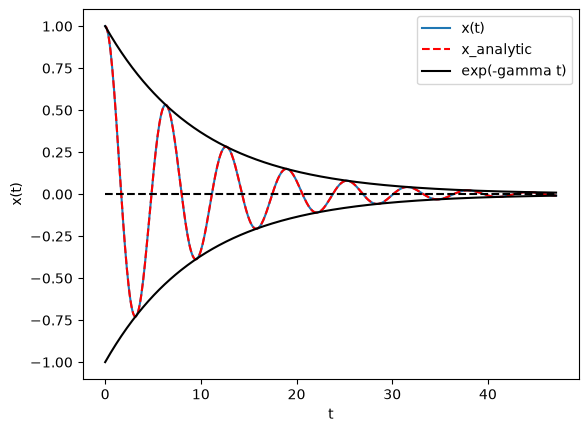

In [11]:

omega = 1.0
gamma = 0.1
m = 1.0

T = 15 * np.pi

t = np.linspace(0.0, T, 500)
yinit = np.array([1.0, 0.])

# standard ode-solver
y = odeint(hom_model, yinit, t, args=(omega, gamma, m), tfirst=True)

plt.plot(t, y[:, 0], label="x(t)")  # y[:,0} is the first column of y
plt.plot(t, weak_damp(t, gamma, omega), '--', color="red", label="x_analytic")
plt.plot(t, np.exp(-gamma * t), '-', color="black", label="exp(-gamma t)")
plt.plot(t, -np.exp(-gamma * t), '-', color="black")
plt.plot(t, np.zeros(len(t)), '--', color="black")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="upper right")
plt.show()


#### 2. Fall: $\gamma = \omega $ -> Aperiodischer Grenzfall

In [15]:
def aperidoic(t, gamma):
    """analytische Lösung aus Übung für x(0) = 1 und dot{x}(0) = 0"""

    return np.exp(-gamma*t)*(1+gamma*t)

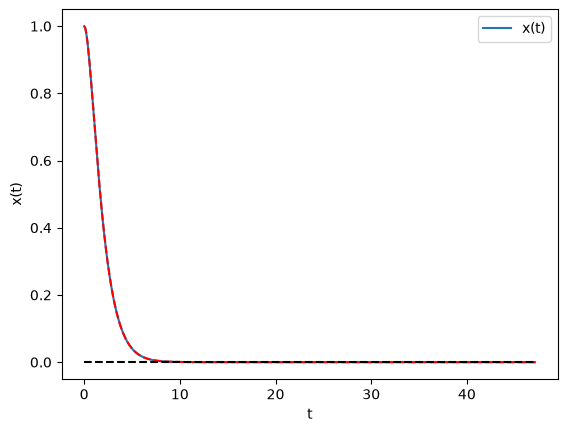

In [ ]:
omega = 1.0
gamma = 1.0
m = 1.0

T = 15 * np.pi

t = np.linspace(0.0, T, 500)
yinit = np.array([1.0, 0.])

# standard ode-solver
y = odeint(hom_model, yinit, t, args=(omega, gamma, m), tfirst=True)

plt.plot(t, y[:, 0], label="x(t)")  # y[:,0} is the first column of y
plt.plot(t, aperidoic(t, gamma), '--', color="red", label="x_analytic")
plt.plot(t, np.zeros(len(t)), '--', color="black")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="upper right")
plt.show()


#### 3. Fall: $\gamma > \omega $ -> Kriechfall

In [17]:
def overdamped(t, gamma, omega):
    """analytische Lösung aus Übung für x(0) = 1 und dot{x}(0) = 0"""

    gamma_tilde = np.sqrt(gamma**2 - omega**2)

    return np.exp(-gamma*t)*(np.cosh(gamma_tilde*t) + (gamma/gamma_tilde)*np.sinh(gamma_tilde*t))


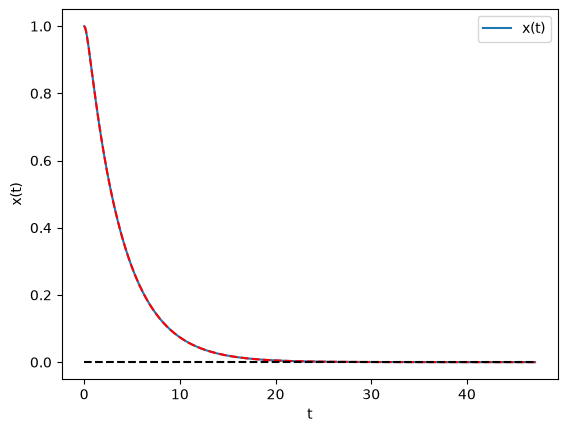

In [ ]:

omega = 1.0
gamma = 2.0
m = 1.0

T = 15 * np.pi

t = np.linspace(0.0, T, 500)
yinit = np.array([1.0, 0.])

# standard ode-solver
y = odeint(hom_model, yinit, t, args=(omega, gamma, m), tfirst=True)

plt.plot(t, y[:, 0], label="x(t)")  # y[:,0} is the first column of y
plt.plot(t, overdamped(t, gamma, omega), '--', color="red", label='x_analytic')
plt.plot(t, np.zeros(len(t)), '--', color="black")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="upper right")
plt.show()